# FNMA transfer instruments: extract, clean and fit
Canonical source: [MMA open-data record](https://dados.mma.gov.br/dataset/fundo-nacional-do-meio-ambiente). Review: [README](../../README.md). Need: `2026-09-br-finance-pathways-review`.
This notebook builds the research release only; it does not approve the dataset for production.

In [1]:
from pathlib import Path
import csv
import importlib.util
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    plt = None

release_candidates = [Path.cwd(), Path.cwd() / 'dataset-review/reviews/br-mma/br-fnma-instrumentos/releases/2025-03']
release_dir = next(path for path in release_candidates if (path / 'build_release.py').exists())
spec = importlib.util.spec_from_file_location('fnma_build', release_dir / 'build_release.py')
build = importlib.util.module_from_spec(spec)
spec.loader.exec_module(build)
{'raw': str(build.RAW), 'output': str(build.OUTPUT)}

{'raw': '/sessions/rcw-01xxn3usjqoysjd3rcayirjg/mnt/CityCatalyst-global-data/dataset-review/reviews/br-mma/br-fnma-instrumentos/releases/2025-03/sample/projetos-fnma-1990-a-2024-dados-abertos-2025.csv',
 'output': '/sessions/rcw-01xxn3usjqoysjd3rcayirjg/mnt/CityCatalyst-global-data/dataset-review/reviews/br-mma/br-fnma-instrumentos/releases/2025-03/data/br_fnma_transfer_instruments.csv'}

In [2]:
# Load raw: zero transformations. See README, Parsing notes.
source_rows = build.load_source()
raw_frame = pd.DataFrame(source_rows)
raw_frame.head(3)

,Ano,Nº do Instrumento de Repasse,Nº Interno,Tema,Instituição Executora,Título do Projeto,UF,Região Geográfica,Cidade da Instituição Executora,Bioma,Esfera Institucional,Data Assinatura,Data de Publicação no DOU,Data de Fim da Vigência,Recursos do FNMA (R$),Recursos de CP (R$),Valor Total do Projeto (R$),Tipo de Seleção do Projeto,Edital ou Termo de Referência de Origem do Projeto
0,1990,,CV001/90,Educação Ambiental,Fundação Nacional do Índio - Funai,I Encontro sobre Meio Ambiente Indígena,DF,Centro-Oeste,,Cerrado,Federal,07/12/1990,,31/12/1990,"2.837,01",0,"2.837,01",Demanda Espontânea (DE),
1,1990,,CV002/90,Gestão de Áreas Protegidas,Núcleo de Cultura Indígena da União das Nações...,Serra do Roncador/Xavante: Manejo Indígena de ...,GO,Centro-Oeste,,Cerrado,OSC,14/11/1990,,31/12/1990,"41.212,07",0,"41.212,07",Demanda Espontânea (DE),
2,1990,,CV003/90,Conservação e Manejo da Biodiversidade,Fundação Pró-natureza – Funatura,Conservação da Avifauna da Amazônia,DF,Centro-Oeste,,Amazônia,OSC,13/11/1990,,31/12/1990,"22.907,20",0,"22.907,20",Demanda Espontânea (DE),


In [3]:
# Clean: trim Unicode whitespace, translate controlled labels, parse dates and BRL, retain source text.
clean_rows = build.clean_rows(source_rows)
clean_frame = pd.DataFrame(clean_rows)
clean_frame.head(3)

,record_id,source_row_number,year,transfer_instrument_id,internal_instrument_id,theme,theme_pt,executing_institution_name,project_title,project_title_pt,...,selection_type,selection_type_pt,origin_call_name,origin_call_name_pt,origin_call_translation_status,translation_status,proper_name_translation_status,record_status,funding_stage,source_url
0,fnma-60faf2b60d81487a,2,1990,,CV001/90,Environmental education,Educação Ambiental,Fundação Nacional do Índio - Funai,,I Encontro sobre Meio Ambiente Indígena,...,Unsolicited demand,Demanda Espontânea (DE),,,not_applicable_missing_source,pending_free_text_translation,not_translated_source_proper_names_preserved,not_stated,signed_transfer_instrument,https://dados.mma.gov.br/dataset/fundo-naciona...
1,fnma-9317b25c5eee247a,3,1990,,CV002/90,Protected-area management,Gestão de Áreas Protegidas,Núcleo de Cultura Indígena da União das Nações...,,Serra do Roncador/Xavante: Manejo Indígena de ...,...,Unsolicited demand,Demanda Espontânea (DE),,,not_applicable_missing_source,pending_free_text_translation,not_translated_source_proper_names_preserved,not_stated,signed_transfer_instrument,https://dados.mma.gov.br/dataset/fundo-naciona...
2,fnma-4375a54246340d46,4,1990,,CV003/90,Biodiversity conservation and management,Conservação e Manejo da Biodiversidade,Fundação Pró-natureza – Funatura,,Conservação da Avifauna da Amazônia,...,Unsolicited demand,Demanda Espontânea (DE),,,not_applicable_missing_source,pending_free_text_translation,not_translated_source_proper_names_preserved,not_stated,signed_transfer_instrument,https://dados.mma.gov.br/dataset/fundo-naciona...


In [4]:
# Validate: structural checks and named source exceptions. Export is blocked if these fail.
build.validate_rows(clean_rows)
validation = {
    'records': len(clean_rows),
    'unique_record_ids': clean_frame['record_id'].nunique(),
    'cancelled_records': int((clean_frame['record_status'] == 'cancelled').sum()),
    'amount_mismatches': int((clean_frame['amount_reconciliation_difference_brl'].astype(float).abs() > 0.01).sum()),
    'project_title_rows_translated': int(clean_frame['project_title'].ne('').sum()),
    'distinct_project_titles_translated': int(clean_frame.loc[clean_frame['project_title'].ne(''), 'project_title_pt'].nunique()),
    'distinct_project_titles_pending': int(clean_frame.loc[clean_frame['project_title'].eq(''), 'project_title_pt'].nunique()),
    'origin_call_rows_translated': int(clean_frame['origin_call_name'].ne('').sum()),
}
pd.Series(validation, name='value')

records                               1495
unique_record_ids                     1495
cancelled_records                       13
amount_mismatches                        1
project_title_rows_translated           74
distinct_project_titles_translated      27
distinct_project_titles_pending       1421
origin_call_rows_translated            531
Name: value, dtype: int64

In [5]:
# Map: one auditable draft decision per source record; medium links require human adjudication.
mapping_rows = build.build_mapping(clean_rows)
mapping_frame = pd.DataFrame(mapping_rows)
mapping_frame.groupby('mapping_confidence').size().rename('records').to_frame()

,records
mapping_confidence,
high,106
medium,756
none,633


In [6]:
# Export only after validation.
build.export_release(clean_rows, mapping_rows)
[build.OUTPUT.name, build.MAPPING.name]

['br_fnma_transfer_instruments.csv',
 'br_fnma_transfer_instruments_to_adaptation_actions.csv']

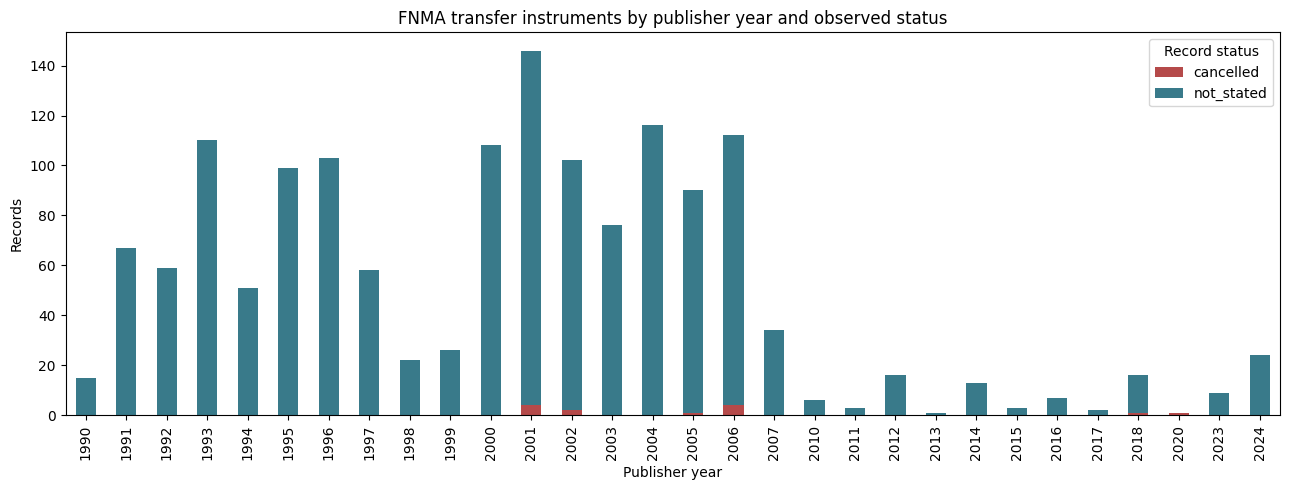

In [7]:
# Visualise and fit: historical volume by year, with cancelled records retained.
year_counts = clean_frame.groupby(['year', 'record_status']).size().unstack(fill_value=0).sort_index()
if plt is not None:
    ax = year_counts.plot(kind='bar', stacked=True, figsize=(13, 5), color=['#b54a4a', '#397a8a'])
    ax.set_title('FNMA transfer instruments by publisher year and observed status')
    ax.set_xlabel('Publisher year')
    ax.set_ylabel('Records')
    ax.legend(title='Record status')
    plt.tight_layout()
    plt.show()
else:
    year_counts.tail()

## Findings

The source contains 1,495 records for 1990–2024, despite the catalogue title saying 1990–2025. Thirteen records are explicitly cancelled, including one cancellation encoded only in the end-date field. The source's three planned-amount fields reconcile in every row except source line 1435, which differs by R$205,306.33. Reviewed English translations cover all 46 non-empty origin-call descriptions and all 27 project titles that repeat; 1,421 singleton titles remain visibly pending. The draft action mapping has complete row coverage and is unchanged, but every medium-confidence link remains pending human adjudication.